#Heart Disease Prediction — Random Forest
**Dataset:** Cleveland Heart Disease (UCI)  
**Algorithm:** Random Forest Classifier  
**Output:** Prediction as Percentage Probability

In [ ]:
#1 : Install / Import Libraries
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', 'scikit-learn', 'pandas',
                'numpy', 'matplotlib', 'seaborn', 'joblib', 'ipywidgets', '-q'])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, cross_val_score)
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, roc_auc_score,
                              ConfusionMatrixDisplay, RocCurveDisplay)

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

print('All libraries loaded successfully!')

All libraries loaded successfully!


In [4]:
# 2 Load & Explore Data 
df = pd.read_csv('heart_cleveland_upload.csv')
df = df.rename(columns={'condition': 'target'})

print('═'*55)
print('  DATASET OVERVIEW')
print('═'*55)
print(f'  Shape            : {df.shape[0]} rows × {df.shape[1]} columns')
print(f'  Missing values   : {df.isnull().sum().sum()}')
print(f'  Duplicate rows   : {df.duplicated().sum()}')
print(f'  No Disease  (0)  : {(df.target==0).sum()} patients')
print(f'  Heart Disease (1): {(df.target==1).sum()} patients')
print('═'*55)
display(df.head())
print()
display(df.describe().round(2))

═══════════════════════════════════════════════════════
  DATASET OVERVIEW
═══════════════════════════════════════════════════════
  Shape            : 297 rows × 14 columns
  Missing values   : 0
  Duplicate rows   : 0
  No Disease  (0)  : 160 patients
  Heart Disease (1): 137 patients
═══════════════════════════════════════════════════════


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00
mean,54.54,0.68,2.16,131.69,247.35,0.14,1.00,149.60,0.33,1.06,0.60,0.68,0.84,0.46
std,9.05,0.47,0.96,17.76,52.00,0.35,0.99,22.94,0.47,1.17,0.62,0.94,0.96,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,2.00,120.00,211.00,0.00,0.00,133.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,56.00,1.00,2.00,130.00,243.00,0.00,1.00,153.00,0.00,0.80,1.00,0.00,0.00,0.00
75%,61.00,1.00,3.00,140.00,276.00,0.00,2.00,166.00,1.00,1.60,1.00,1.00,2.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,3.00,2.00,1.00


In [ ]:
# 3 Train Random Forest (GridSearchCV)
df_clean = df.drop_duplicates()
X = df_clean.drop(columns='target')
y = df_clean['target']
FEATURE_NAMES = list(X.columns)

# Stratified split  →  preserves class ratio in train & test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.18, random_state=11, stratify=y
)

print(f'Train size: {len(X_train)}   Test size: {len(X_test)}')
print('Running GridSearchCV (this takes ~30 seconds)…')

param_grid = {
    'n_estimators':      [100, 200, 300],
    'max_depth':         [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf':  [1, 2],
    'max_features':      ['sqrt', 'log2'],
    'criterion':         ['gini', 'entropy'],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)
grid_search.fit(X_train, y_train)

MODEL = grid_search.best_estimator_

print(f'\n Best Parameters : {grid_search.best_params_}')
print(f'   Best CV AUC     : {grid_search.best_score_:.4f}')

# Save model
joblib.dump({'model': MODEL, 'feature_names': FEATURE_NAMES}, 'rf_heart_model.pkl')
print('   Model saved → rf_heart_model.pkl')

Train size: 243   Test size: 54
Running GridSearchCV (this takes ~30 seconds)…


In [ ]:
# Full Evaluation Metrics 
y_pred       = MODEL.predict(X_test)
y_pred_proba = MODEL.predict_proba(X_test)[:, 1]

train_acc  = accuracy_score(y_train, MODEL.predict(X_train))
test_acc   = accuracy_score(y_test,  y_pred)
auc_score  = roc_auc_score(y_test,   y_pred_proba)

cv_acc = cross_val_score(MODEL, X, y, cv=cv_strategy, scoring='accuracy')
cv_auc = cross_val_score(MODEL, X, y, cv=cv_strategy, scoring='roc_auc')

cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print('═'*55)
print(' MODEL EVALUATION RESULTS')
print('═'*55)
print(f'  Training  Accuracy     : {train_acc*100:.2f} %')
print(f'  Testing   Accuracy     : {test_acc*100:.2f} %')
print(f'  AUC-ROC                : {auc_score:.4f}')
print(f'  Sensitivity (Recall)   : {sensitivity*100:.2f} %')
print(f'  Specificity            : {specificity*100:.2f} %')
print(f'  CV Accuracy (5-fold)   : {cv_acc.mean()*100:.2f} % ± {cv_acc.std()*100:.2f}')
print(f'  CV AUC      (5-fold)   : {cv_auc.mean():.4f}  ± {cv_auc.std():.4f}')
print('═'*55)
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['No Disease','Heart Disease']))

# Plots 
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Confusion matrix
ConfusionMatrixDisplay(cm, display_labels=['No Disease','Heart Disease']).plot(
    ax=axes[0], colorbar=False, cmap='Reds')
axes[0].set_title('Confusion Matrix', fontsize=13, pad=10)

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_pred_proba, ax=axes[1],
                                  name=f'Random Forest (AUC={auc_score:.3f})', color='crimson')
axes[1].plot([0,1],[0,1],'--', color='gray', lw=1)
axes[1].set_title('ROC Curve', fontsize=13, pad=10)

plt.tight_layout()
plt.savefig('evaluation_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved → evaluation_plots.png')

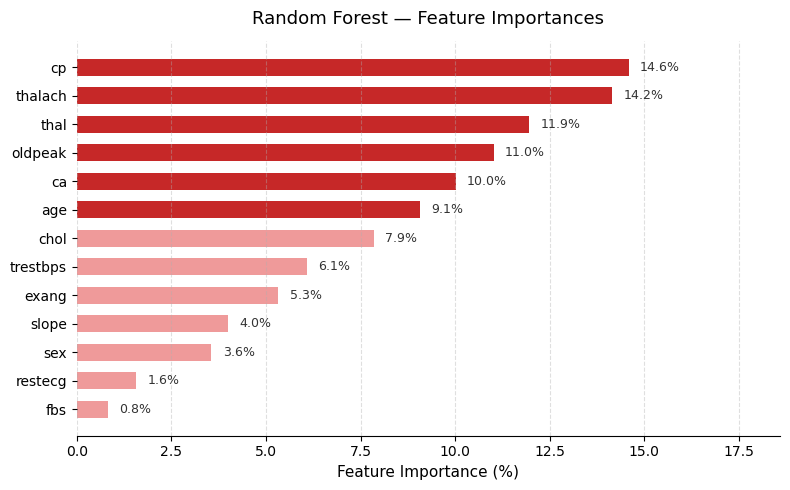

Plot saved → feature_importance.png


In [5]:
# Feature Importance Plot 
importances = pd.Series(MODEL.feature_importances_, index=FEATURE_NAMES)\
                .sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#c62828' if imp > importances.median() else '#ef9a9a' for imp in importances]
bars = ax.barh(importances.index, importances.values * 100, color=colors, edgecolor='none', height=0.6)

for bar, val in zip(bars, importances.values * 100):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=9, color='#333')

ax.set_xlabel('Feature Importance (%)', fontsize=11)
ax.set_title('Random Forest — Feature Importances', fontsize=13, pad=12)
ax.set_xlim(0, importances.max() * 100 + 4)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='y', labelsize=10)
ax.xaxis.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved → feature_importance.png')

---
###  Feature Reference
| Feature | Description |
|---|---|
| age | Age in years |
| sex | 0 = Female, 1 = Male |
| cp | Chest pain: 0=typical angina, 1=atypical, 2=non-anginal, 3=asymptomatic |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1=yes) |
| restecg | Resting ECG: 0=normal, 1=ST-T abnormality, 2=LV hypertrophy |
| thalach | Maximum heart rate achieved |
| exang | Exercise induced angina (1=yes) |
| oldpeak | ST depression induced by exercise vs rest |
| slope | Slope of peak exercise ST: 0=up, 1=flat, 2=down |
| ca | Major vessels coloured by fluoroscopy (0–3) |
| thal | 0=normal, 1=fixed defect, 2=reversible defect |